# TuniShop — Machine learning 06. Prédiction du retard de livraison

**Auteure :** Sarra Abdeljaouad · **Phase :** machine learning · **Source :** TuniShop_DWH (vues `bi`), via `05_Data/features` · **Découpage :** apprentissage 2023-2024, test 2025

*Notebook ajouté à l'arborescence de départ (cas validé lors du cadrage). Il s'exécute avant `05_Evaluation_Modeles`.*

## Objectif

Prédire, **le jour de l'expédition**, si un colis arrivera en retard, pour prévenir le client ou choisir un autre transporteur.

**Difficulté connue (EDA) :** forte dérive. Le taux de retard passe de 12,2 % (apprentissage) à 17,3 % (test), surtout à cause de SahelLog à partir de juillet 2024. Un modèle qui apprend sur tout l'historique risque de **sous-estimer** 2025. On teste donc aussi des modèles appris sur une **fenêtre récente**.

| Modèle | Fenêtres testées |
|---|---|
| Règle « taux de retard du transporteur sur les 6 derniers mois » | **référence** |
| Régression logistique | tout l'historique, 12 derniers mois, 6 derniers mois |
| Gradient boosting | tout l'historique, 12 derniers mois, 6 derniers mois |

**Validation (sans toucher au test) :** fin de l'apprentissage simulée au 30/06/2024, validation sur le 2nd semestre 2024. Le modèle retenu est ensuite réappris avec la même fenêtre jusqu'au 31/12/2024, puis évalué sur 2025.

## 0. Préparation

In [1]:
# --- Bibliothèques
import sys
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

# --- Module commun du projet (dossier 00_Commun)
sys.path.insert(0, "../00_Commun")
from tunishop_analytics import config as cfg, chargement, features, temporal_split, validation, publication

warnings.filterwarnings("ignore")
cfg.appliquer_style()
sql = chargement.requete                       # sql("SELECT ...") -> exécuté par SQL Server
pd.set_option("display.float_format", lambda v: f"{v:,.3f}".replace(",", " "))

def montrer(nom):
    """Enregistre la figure en cours dans 06_Exports/Figures/<nom>.png, puis l'affiche."""
    cfg.sauver_figure(plt.gcf(), nom)
    plt.show()

for dossier in (cfg.DOSSIER_MODELES, cfg.DOSSIER_PREDICTIONS):
    dossier.mkdir(parents=True, exist_ok=True)

from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline

In [2]:
chargement.ouvrir_connexion()

retard = features.lire("ml_retard")
X_COLS, CIBLE = features.colonnes_ml("retard"), "en_retard"
app, test = retard[retard["periode"] == "apprentissage"], retard[retard["periode"] == "test"]

# 🔗 Contrôle SQL direct : taux de retard 2025 des expéditions livrées
t_sql = sql("""
    SELECT COUNT(*) AS livrees, 1.0 * SUM(CASE WHEN l.retard_j > 0 THEN 1 ELSE 0 END) / COUNT(*) AS taux_retard
    FROM bi.v_fact_livraisons l JOIN bi.v_dim_date d ON d.date_sk = l.date_expedition_sk
    WHERE l.est_livree = 1 AND d.annee = 2025""")
t_sql["jeu de données"] = f"{len(test)} livrées, {test[CIBLE].mean():.4f}"
t_sql

Connecté à TuniShop_DWH sur localhost (pilote : ODBC Driver 17 for SQL Server)


,livrees,taux_retard,jeu de données
0,26590,0.173,"26590 livrées, 0.1733"


## 1. Choix du modèle et de la fenêtre sur la validation (2nd semestre 2024)

In [3]:
def regle_transporteur(historique, cible_df, mois=6):
    """Référence : taux de retard de chaque transporteur sur les `mois` derniers mois de l'historique."""
    debut = historique["date_expedition"].max() - pd.DateOffset(months=mois)
    taux = historique[historique["date_expedition"] > debut].groupby("transporteur")[CIBLE].mean()
    return cible_df["transporteur"].map(taux).fillna(historique[CIBLE].mean()).values

def fenetre(t, fin, mois):
    return t[t["date_expedition"] <= fin] if mois is None else t[(t["date_expedition"] <= fin) & (t["date_expedition"] > fin - pd.DateOffset(months=mois))]

FIN_VALID = pd.Timestamp("2024-06-30")
val = app[app["date_expedition"] > FIN_VALID]
familles = {"Régression logistique": lambda: LogisticRegression(max_iter=3000),
            "Gradient boosting": lambda: HistGradientBoostingClassifier(learning_rate=0.05, max_iter=300, max_leaf_nodes=15, random_state=0)}
FENETRES = {"tout l'historique": None, "12 derniers mois": 12, "6 derniers mois": 6}
choix = [{"modele": "Règle transporteur 6 mois (référence)", "fenetre": "6 derniers mois",
          "AUC validation": validation.metriques_classification(val[CIBLE], regle_transporteur(app[app["date_expedition"] <= FIN_VALID], val))["AUC"]}]
for famille, fabrique in familles.items():
    for nom_f, mois in FENETRES.items():
        donnees = fenetre(app, FIN_VALID, mois)
        pipe = make_pipeline(features.preprocesseur("retard", echelle=famille.startswith("Régression")), fabrique()).fit(donnees[X_COLS], donnees[CIBLE])
        p = pipe.predict_proba(val[X_COLS])[:, 1]
        m = validation.metriques_classification(val[CIBLE], p)
        choix.append({"modele": famille, "fenetre": nom_f, "lignes": len(donnees), "AUC validation": m["AUC"],
                      "taux prévu": m["taux_prevu"], "taux réel": m["taux_reel"]})
choix = pd.DataFrame(choix).sort_values("AUC validation", ascending=False).reset_index(drop=True)
cfg.exporter_table(choix, "ML06_validation", index=False)
choix

Publication : connecté à TuniShop_ANALYTICS sur localhost
  ✔ ana.ml06_validation                               7 lignes


,modele,fenetre,AUC validation,lignes,taux prévu,taux réel
0,Régression logistique,tout l'historique,0.729,21 809.000,0.094,0.165
1,Régression logistique,12 derniers mois,0.726,15 811.000,0.094,0.165
2,Gradient boosting,tout l'historique,0.711,21 809.000,0.093,0.165
3,Gradient boosting,12 derniers mois,0.709,15 811.000,0.093,0.165
4,Régression logistique,6 derniers mois,0.696,8 534.000,0.091,0.165
5,Gradient boosting,6 derniers mois,0.673,8 534.000,0.070,0.165
6,Règle transporteur 6 mois (référence),6 derniers mois,0.640,NaN,NaN,NaN


> **Lecture.** Sur la validation (2nd semestre 2024), la **régression logistique sur tout l'historique** est la meilleure (AUC 0,729) ; contrairement à l'intuition, les fenêtres récentes (12 ou 6 mois) font moins bien : moins de données, et la dérive de SahelLog commence justement pendant la validation. Tous les modèles **sous-estiment** déjà le taux de retard en validation (9 % prévu contre 16,5 % réel).

## 2. Apprentissage final et test sur 2025

In [4]:
FIN_APP = temporal_split.FIN_APPRENTISSAGE
resultats, probas, finals = [], {}, {}
p_ref = regle_transporteur(app, test)
probas["Règle transporteur 6 mois (référence)"] = p_ref
seuil_ref = validation.meilleur_seuil(val[CIBLE], regle_transporteur(app[app["date_expedition"] <= FIN_VALID], val))
resultats.append({"cas": "retard", "modele": "Règle transporteur 6 mois (référence)", "fenetre": "6 derniers mois", "role": "référence",
                  "AUC_validation": choix.loc[choix["modele"].str.startswith("Règle"), "AUC validation"].iloc[0],
                  **validation.metriques_classification(test[CIBLE], p_ref, seuil=seuil_ref)})
for famille, fabrique in familles.items():
    # meilleure fenêtre de la famille sur la validation
    meilleure = choix[choix["modele"] == famille].iloc[0]
    mois = FENETRES[meilleure["fenetre"]]
    pipe_v = make_pipeline(features.preprocesseur("retard", echelle=famille.startswith("Régression")), fabrique()).fit(
        fenetre(app, FIN_VALID, mois)[X_COLS], fenetre(app, FIN_VALID, mois)[CIBLE])
    seuil = validation.meilleur_seuil(val[CIBLE], pipe_v.predict_proba(val[X_COLS])[:, 1])
    donnees = fenetre(app, FIN_APP, mois)
    pipe = make_pipeline(features.preprocesseur("retard", echelle=famille.startswith("Régression")), fabrique()).fit(donnees[X_COLS], donnees[CIBLE])
    nom = f"{famille} ({meilleure['fenetre']})"
    finals[nom], probas[nom] = pipe, pipe.predict_proba(test[X_COLS])[:, 1]
    resultats.append({"cas": "retard", "modele": nom, "fenetre": meilleure["fenetre"], "role": "candidat",
                      "AUC_validation": meilleure["AUC validation"],
                      "AUC_apprentissage": validation.metriques_classification(donnees[CIBLE], pipe.predict_proba(donnees[X_COLS])[:, 1])["AUC"],
                      **validation.metriques_classification(test[CIBLE], probas[nom], seuil=seuil)})
resultats = pd.DataFrame(resultats)
RETENU = resultats[resultats["role"] == "candidat"].sort_values("AUC_validation", ascending=False).iloc[0]["modele"]
resultats["retenu"] = resultats["modele"] == RETENU
cfg.exporter_table(resultats, "ML_metriques_retard", index=False)
resultats.set_index("modele").drop(columns=["cas"]).T

  ✔ ana.ml_metriques_retard                           3 lignes


modele,Règle transporteur 6 mois (référence),Régression logistique (tout l'historique),Gradient boosting (tout l'historique)
fenetre,6 derniers mois,tout l'historique,tout l'historique
role,référence,candidat,candidat
AUC_validation,0.640,0.729,0.711
AUC,0.728,0.811,0.795
precision_moyenne,0.309,0.501,0.483
precision,0.267,0.381,0.278
rappel,0.835,0.692,0.886
F1,0.405,0.492,0.424
seuil,0.080,0.130,0.060
taux_reel,0.173,0.173,0.173


> **Lecture.** Sur 2025, la **régression logistique** atteint une **AUC de 0,811** contre 0,728 pour la règle « taux du transporteur sur 6 mois » (+11,4 %). En ciblant les 20 % d'expéditions les plus risquées, on trouve **52 % des retards** (taux de retard de 45 % dans ce groupe, contre 17 % en moyenne). Au seuil choisi sur la validation (0,13), précision 38 % et rappel 69 %. Le gradient boosting sur-apprend davantage (0,843 → 0,795).

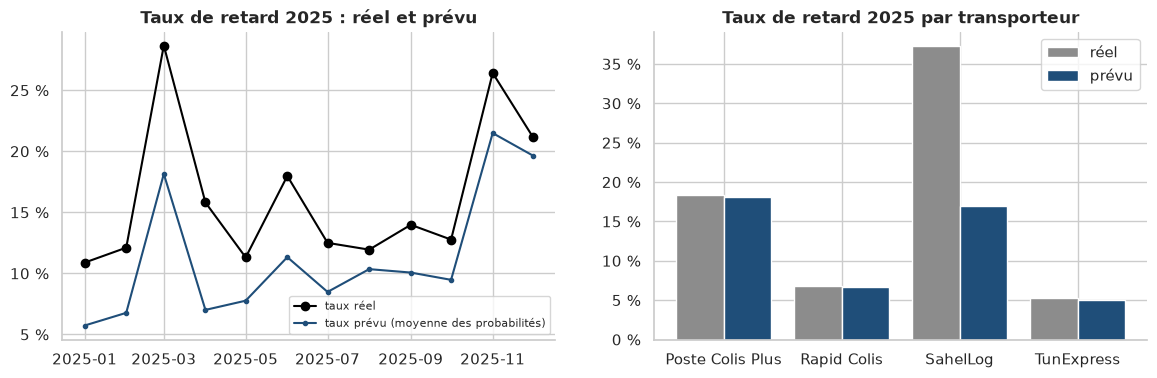

  ✔ ana.ml06_par_transporteur                         4 lignes


,expeditions,taux_reel,taux_prevu,AUC
transporteur,,,,
Poste Colis Plus,8 013.000,0.183,0.181,0.773
Rapid Colis,7 645.000,0.068,0.066,0.777
SahelLog,6 396.000,0.373,0.170,0.770
TunExpress,4 536.000,0.053,0.050,0.786


In [5]:
# Le modèle retenu suit-il la dérive de 2025 ? Taux prévu et réel par mois, et AUC par transporteur
t = test.assign(proba=probas[RETENU])
mensuel = t.groupby(t["date_expedition"].dt.to_period("M"))[[CIBLE, "proba"]].mean()
par_transporteur = t.groupby("transporteur").apply(lambda g: pd.Series({
    "expeditions": len(g), "taux_reel": g[CIBLE].mean(), "taux_prevu": g["proba"].mean(),
    "AUC": validation.metriques_classification(g[CIBLE], g["proba"])["AUC"]}))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(mensuel.index.to_timestamp(), mensuel[CIBLE], color="black", marker="o", label="taux réel")
axes[0].plot(mensuel.index.to_timestamp(), mensuel["proba"], color=cfg.BLEU, marker=".", label="taux prévu (moyenne des probabilités)")
axes[0].set_title("Taux de retard 2025 : réel et prévu"); cfg.format_pourcent(axes[0]); axes[0].legend(fontsize=8)
x = np.arange(len(par_transporteur))
axes[1].bar(x - 0.2, par_transporteur["taux_reel"], 0.4, color=cfg.GRIS, label="réel")
axes[1].bar(x + 0.2, par_transporteur["taux_prevu"], 0.4, color=cfg.BLEU, label="prévu")
axes[1].set_xticks(x, par_transporteur.index); axes[1].set_title("Taux de retard 2025 par transporteur"); cfg.format_pourcent(axes[1]); axes[1].legend()
montrer("ML06_1_retard_2025")
cfg.exporter_table(par_transporteur, "ML06_par_transporteur")
par_transporteur

> **Lecture.** Le modèle **classe bien** les expéditions de chaque transporteur (AUC de 0,77 à 0,79) et prévoit le bon taux pour Poste Colis Plus, Rapid Colis et TunExpress. Mais pour **SahelLog**, il prévoit 17 % de retards au lieu de **37 %** : il a appris surtout sur la période où SahelLog était fiable. C'est la dérive de relation repérée dans la préparation : le **classement** reste bon, le **niveau** est faux.

## 3. Sauvegarde

In [6]:
joblib.dump({"pipeline": finals[RETENU], "seuil": float(resultats.set_index("modele").loc[RETENU, "seuil"]),
             "fenetre": resultats.set_index("modele").loc[RETENU, "fenetre"], "variables": X_COLS,
             "conseil": "réapprendre chaque mois sur la même fenêtre glissante"}, cfg.DOSSIER_MODELES / "retard_modele.joblib")
pred = test[["livraison_id", "date_expedition", "transporteur", CIBLE]].copy()
pred["proba_retard"] = probas[RETENU]
cfg.exporter_resultat(pred, cfg.DOSSIER_PREDICTIONS / "retard_2025_test.parquet")
print("Modèle : 06_Exports/Modeles/retard_modele.joblib ; prédictions : 06_Exports/Predictions/retard_2025_test.parquet")

  ✔ ana.ml_pred_retard_2025                      26 590 lignes
Modèle : 06_Exports/Modeles/retard_modele.joblib ; prédictions : 06_Exports/Predictions/retard_2025_test.parquet


## 4. Synthèse

> **Lecture.** **Modèle retenu : régression logistique** (AUC 2025 de 0,811 contre 0,728 pour la référence ; 52 % des retards trouvés dans le top 20 %). Limite : il sous-estime le niveau de retard de SahelLog (17 % prévu, 37 % réel). **Recommandation :** réapprendre le modèle chaque mois et recalibrer les probabilités par transporteur sur les dernières semaines ; suivre le taux réel par transporteur comme alerte. Fichiers : `06_Exports/Modeles/retard_modele.joblib`, `06_Exports/Predictions/retard_2025_test.parquet`.

In [7]:
chargement.fermer_connexion()

Connexion fermée.
